**Profe, hace unos meses estuve aprendiendo un poco de computación cuántica y trabajé en una simulación del modelo de Ising en 1D con campo transversal, haciendo una trotterización del Hamiltoniano para estudiar la evolución temporal de la magnetización.**

**Como está relacionado con el laboratorio anterior, me pareció interesante compartírselo. Le pedí a la IA que me ayudara a organizar el notebook y a documentar el código y la teoría detrás de la implementación.**

# Simulación cuántica del modelo de Ising transversal

Como extensión del laboratorio anterior de Monte Carlo, se estudia la dinámica cuántica de una cadena abierta de cuatro espines mediante circuitos cuánticos. A diferencia del muestreo térmico clásico, aquí se simula la evolución unitaria desde el estado $|0000\rangle$.

## 1. Hamiltoniano y parámetros

En unidades $\hbar=1$:

$$H=H_X+H_{ZZ}=-h\sum_{i=1}^{N}X_i-J\sum_{i=1}^{N-1}Z_iZ_{i+1}.$$

Se fija $J=1$ y se estudian diferentes valores de $h/J$.

In [1]:
%pip install -q qiskit qiskit-aer pylatexenc scipy matplotlib

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
nq = 4
J = 1.0
target_dt = 0.01
shots = 1000
n_repetitions = 20
hj_values = [0, 1, 2, 3, 4]
t_values = np.linspace(0, 5, 20)
t_exact = np.linspace(0, 5, 200)
simulator = AerSimulator()

## 2. Circuito cuántico: descomposición de Trotter

Dado que $[H_X,H_{ZZ}]\neq0$ en general, se utiliza la aproximación de primer orden

$$U(t)\approx\left[e^{-iH_{ZZ}\Delta t}e^{-iH_X\Delta t}\right]^k,\qquad \Delta t=t/k.$$

El campo transversal se implementa mediante $R_x(-2h\Delta t)$ y la interacción entre vecinos mediante $CNOT–R_z(-2J\Delta t)–CNOT$. Cada paso aplica primero el campo transversal y después la interacción.

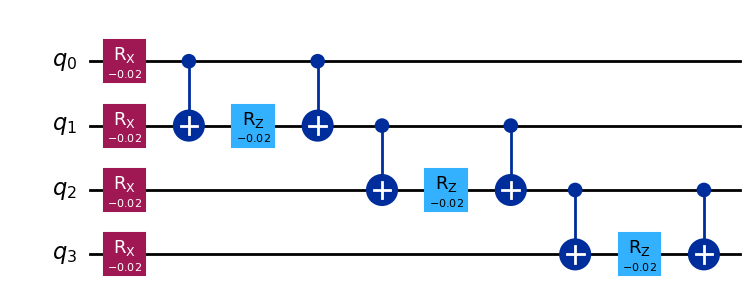

In [3]:
def trotter_step(h, dt):
    qc = QuantumCircuit(nq, name="Trotter")
    for i in range(nq):
        qc.rx(-2 * h * dt, i)
    for i in range(nq - 1):
        qc.cx(i, i + 1)
        qc.rz(-2 * J * dt, i + 1)
        qc.cx(i, i + 1)
    return qc
def ising_circuit(t, h_j):
    k = max(1, int(np.ceil(t / target_dt)))
    dt = t / k
    step = trotter_step(h_j * J, dt).to_instruction()
    qc = QuantumCircuit(nq)
    for _ in range(k):
        qc.append(step, range(nq))
    qc.measure_all()
    return qc
# Visualización de un paso (no del circuito completo)
trotter_step(h=J, dt=target_dt).draw("mpl")

## 3. Medición de la magnetización

$$\langle M_z(t)\rangle=\frac{1}{N}\sum_{i=1}^N\langle Z_i\rangle.$$

Cada bit medido aporta $+1$ si es 0 y $-1$ si es 1. Para un resultado binario $s$, su magnetización es $m(s)=1-2n_1(s)/N$. El promedio se estima con las frecuencias de los resultados del circuito.

Magnetización: 0.1510


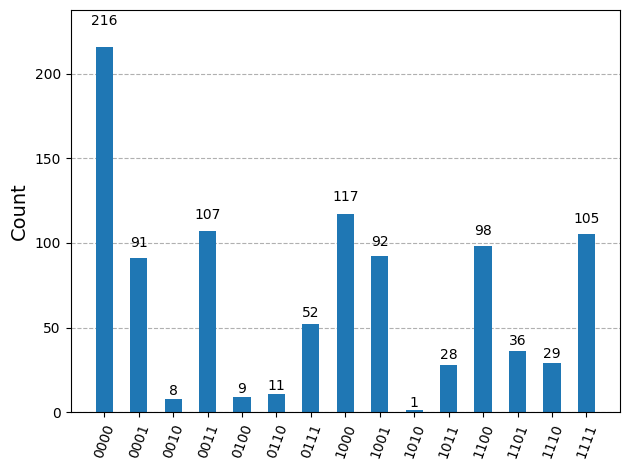

In [8]:
def magnetization(counts):
    total = sum(counts.values())
    return sum((1 - 2 * state.count("1") / nq) * freq
               for state, freq in counts.items()) / total
# Ejemplo: distribución de resultados para t=1 y h/J=1
qc = transpile(ising_circuit(1, 1), simulator)
counts = simulator.run(qc, shots=shots, seed_simulator=42).result().get_counts()
print(f"Magnetización: {magnetization(counts):.4f}")
plot_histogram(counts)

## 4. Evolución temporal exacta (referencia clásica)

Se calcula el mismo observable mediante la exponencial matricial del Hamiltoniano completo. Esta referencia permite distinguir discrepancias de Trotter de las fluctuaciones de muestreo.

In [5]:
I = np.eye(2)
X = np.array([[0, 1],
              [1, 0]])
Z = np.array([[1,  0],
              [0, -1]])
def op_n(*ops):
    result = ops[0]
    for op in ops[1:]:
        result = np.kron(result, op)
    return result
def calculate_mz_exact(t, h_j):
    j = J
    h = h_j * j
    # Hamiltoniano vacío
    H = np.zeros((2**nq, 2**nq), dtype=complex)
    for i in range(nq):
        ops = [I] * nq
        ops[i] = X
        H -= h * op_n(*ops)
    for i in range(nq - 1):
        ops = [I] * nq
        ops[i] = Z
        ops[i + 1] = Z
        H -= j * op_n(*ops)
    # Estado inicial |0000>
    psi0 = np.zeros(2**nq, dtype=complex)
    psi0[0] = 1
    # Evolución exacta
    psi_t = expm(-1j * H * t) @ psi0
    # Magnetización promedio
    mz = 0
    for i in range(nq):
        ops = [I] * nq
        ops[i] = Z
        Zi = op_n(*ops)
        mz += np.vdot(psi_t, Zi @ psi_t).real
    return mz / nq

## 5. Simulación y comparación

Para cada instante y relación $h/J$, se realizan 20 ejecuciones de 1000 mediciones. Las barras de error representan la desviación estándar entre ejecuciones, no el error estándar de la media ni el error de Trotter. Se transpila una vez por circuito y se reutiliza para las repeticiones.

In [6]:
mz_exact = np.array([[calculate_mz_exact(t, hj) for t in t_exact]
                     for hj in hj_values])

mz_trotter = np.zeros((len(hj_values), len(t_values)))
mz_std = np.zeros_like(mz_trotter)

for i, hj in enumerate(hj_values):
    circuits = transpile([ising_circuit(t, hj) for t in t_values],
                         simulator, optimization_level=1)
    # Las repeticiones son experimentos de medición separados.
    batch = [qc for qc in circuits for _ in range(n_repetitions)]
    result = simulator.run(batch, shots=shots, seed_simulator=42+i).result()
    for j, t in enumerate(t_values):
        samples = [magnetization(result.get_counts(j*n_repetitions+r))
                   for r in range(n_repetitions)]
        mz_trotter[i, j] = np.mean(samples)
        mz_std[i, j] = np.std(samples, ddof=1)

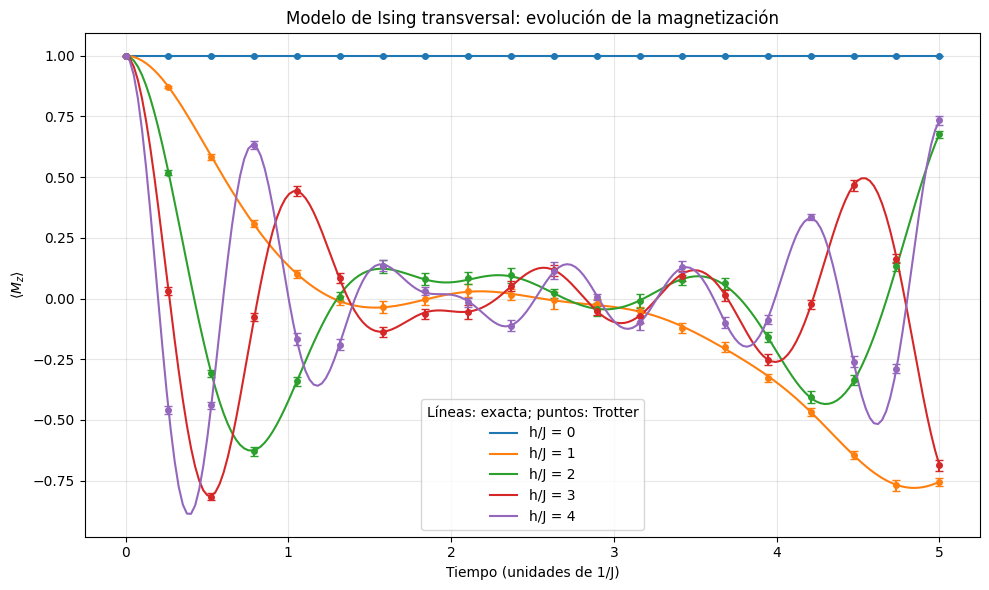

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
for i, hj in enumerate(hj_values):
    line, = ax.plot(t_exact, mz_exact[i], label=f"h/J = {hj}")
    ax.errorbar(t_values, mz_trotter[i], yerr=mz_std[i],
                fmt="o", color=line.get_color(), capsize=3, markersize=4)
ax.set_xlabel("Tiempo (unidades de 1/J)")
ax.set_ylabel(r"$\langle M_z \rangle$")
ax.set_title("Modelo de Ising transversal: evolución de la magnetización")
ax.legend(title="Líneas: exacta; puntos: Trotter")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 6. Interpretación física

Para $h/J=0$, el estado inicial es un autoestado del Hamiltoniano, por lo que $\langle M_z\rangle=1$ en todo momento. Cuando $h\neq0$, el término transversal induce transiciones entre configuraciones de espín y la magnetización puede oscilar. La comparación con la evolución exacta permite evaluar la aproximación digital, mientras que las barras de error cuantifican las fluctuaciones debidas al número finito de mediciones.

La implementación utiliza un simulador ideal de circuitos cuánticos (AerSimulator), no hardware cuántico físico.